# 05 · Lluvia mensual en la Altillanura (CHIRPS) y su relación con el fuego

**Fuente:** CHIRPS Daily v2.0 (UCSB Climate Hazards Center), vía Google
Earth Engine (`UCSB-CHG/CHIRPS/DAILY`), ~5 km, 1981–2025.

**Propósito:**
1. Calcular la lluvia mensual promedio de cada municipio.
2. Construir anomalías respecto a la normal 1991–2020.
3. Probar la cadena El Niño → lluvia → fuego.

**Entradas:** `altillanura_municipios.gpkg`, `oni_mensual.csv`,
`fuego_oni_temporadas.csv`, `firms_mensual_municipio.csv`.

**Salidas:** `chirps_mensual_municipio.csv`, `clima_fuego_temporadas.csv`.

## Paso 1. Preparar el entorno y conectar Earth Engine

In [1]:
from google.colab import drive
drive.mount('/content/drive')

RUTA = '/content/drive/MyDrive/proyecto-altillanura-STDG'
PROCESADOS = f'{RUTA}/datos/procesados'
FIGURAS = f'{RUTA}/resultados/figuras'

import os, json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats
import ee

PROYECTO = 'altillanura-stdg'

ee.Authenticate()
ee.Initialize(project=PROYECTO)
print('Earth Engine conectado')

Mounted at /content/drive
Earth Engine conectado


## Paso 2. Subir los límites de los municipios a Earth Engine
Se simplifican los bordes (~500 m) para que la consulta sea liviana;
con píxeles de 5 km, eso no cambia el resultado.

In [2]:
mpios = gpd.read_file(f'{PROCESADOS}/altillanura_municipios.gpkg')
area = mpios.set_index('mpio_cdpmp')['area_km2']   # para promedios ponderados

m4326 = mpios[['mpio_cdpmp', 'mpio_cnmbr', 'geometry']].to_crs(4326)
m4326['geometry'] = m4326.geometry.simplify(0.005, preserve_topology=True)

fc = ee.FeatureCollection(json.loads(m4326.to_json()))
print('Municipios en Earth Engine:', fc.size().getInfo())
print(fc.aggregate_array('mpio_cnmbr').getInfo())

Municipios en Earth Engine: 7
['MAPIRIPÁN', 'PUERTO GAITÁN', 'PUERTO LÓPEZ', 'PUERTO CARREÑO', 'LA PRIMAVERA', 'SANTA ROSALÍA', 'CUMARIBO']


## Paso 3. Lluvia mensual por municipio, 1981–2025
Para cada mes se suma la lluvia diaria (mm/mes) y se promedia dentro de
cada municipio. Se hace una consulta por año (12 meses a la vez).
Si el archivo ya existe en Drive, se carga en lugar de descargar de nuevo.

In [3]:
salida = f'{PROCESADOS}/chirps_mensual_municipio.csv'

if os.path.exists(salida):
    lluvia = pd.read_csv(salida, dtype={'mpio_cdpmp': str})
    print('Cargado desde Drive:', len(lluvia), 'filas')
else:
    chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').select('precipitation')
    filas = []
    for anio in range(1981, 2026):
        bandas = []
        for m in range(1, 13):
            ini = ee.Date.fromYMD(anio, m, 1)
            bandas.append(chirps.filterDate(ini, ini.advance(1, 'month'))
                          .sum().rename(f'm{m:02d}'))
        img = ee.Image.cat(bandas)
        res = img.reduceRegions(collection=fc, reducer=ee.Reducer.mean(),
                                scale=5566).getInfo()
        for f in res['features']:
            p = f['properties']
            for m in range(1, 13):
                filas.append({'mpio_cdpmp': p['mpio_cdpmp'],
                              'mpio_cnmbr': p['mpio_cnmbr'],
                              'mes': f'{anio}-{m:02d}',
                              'lluvia_mm': p.get(f'm{m:02d}')})
        if anio % 5 == 0:
            print('  listo hasta', anio)
    lluvia = pd.DataFrame(filas)
    lluvia.to_csv(salida, index=False)
    print('Descargado y guardado:', len(lluvia), 'filas')

lluvia['fecha'] = pd.PeriodIndex(lluvia['mes'], freq='M').to_timestamp()
print('Valores faltantes:', lluvia['lluvia_mm'].isna().sum())

  listo hasta 1985
  listo hasta 1990
  listo hasta 1995
  listo hasta 2000
  listo hasta 2005
  listo hasta 2010
  listo hasta 2015
  listo hasta 2020
  listo hasta 2025
Descargado y guardado: 3780 filas
Valores faltantes: 0


## Paso 4. Validación: lluvia anual y ciclo estacional
Se compara el ciclo de la lluvia con el del fuego. El promedio regional
se pondera por el área de cada municipio.

Lluvia anual promedio 1991–2020 (mm):
mpio_cnmbr
CUMARIBO          2867.0
MAPIRIPÁN         2775.0
PUERTO LÓPEZ      2718.0
LA PRIMAVERA      2651.0
PUERTO GAITÁN     2592.0
SANTA ROSALÍA     2565.0
PUERTO CARREÑO    2452.0


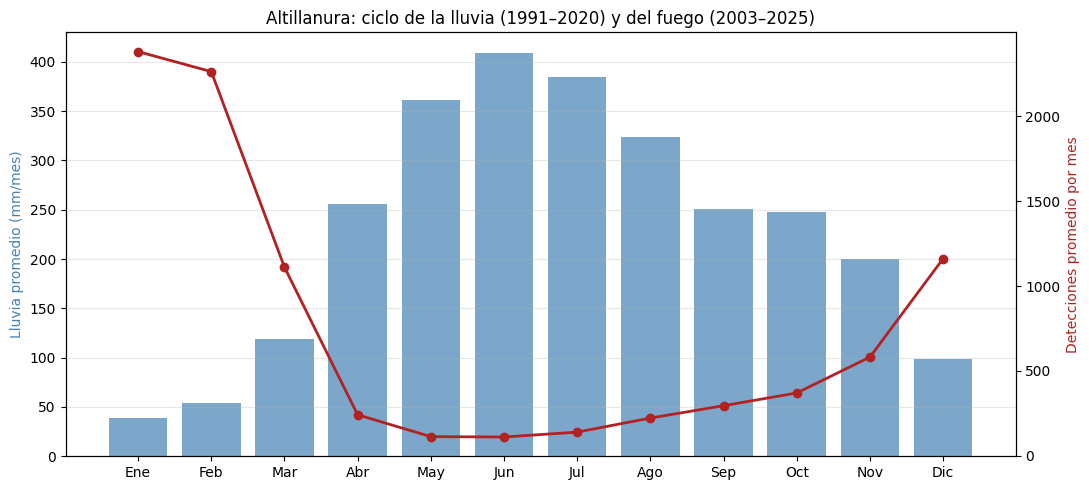


Lluvia anual regional promedio: 2742 mm


In [4]:
# Lluvia anual promedio por municipio (normal 1991–2020)
lluvia['anio'] = lluvia['fecha'].dt.year
anual = lluvia.groupby(['mpio_cnmbr', 'anio'])['lluvia_mm'].sum().reset_index()
normal = anual[anual['anio'].between(1991, 2020)].groupby('mpio_cnmbr')['lluvia_mm'].mean()
print('Lluvia anual promedio 1991–2020 (mm):')
print(normal.sort_values(ascending=False).round(0).to_string())

# Serie regional ponderada por área
lluvia['w'] = lluvia['mpio_cdpmp'].map(area)
region = (lluvia.assign(lw=lluvia['lluvia_mm'] * lluvia['w'])
          .groupby('fecha')[['lw', 'w']].sum())
region = region['lw'] / region['w']

# Ciclo estacional de la lluvia (1991–2020) y del fuego (2003–2025)
ciclo_lluvia = region.loc['1991':'2020'].groupby(region.loc['1991':'2020'].index.month).mean()

firms = pd.read_csv(f'{PROCESADOS}/firms_mensual_municipio.csv', dtype={'mpio_cdpmp': str})
firms['fecha'] = pd.PeriodIndex(firms['mes'], freq='M').to_timestamp()
fuego_reg = firms.groupby('fecha')['focos_total'].sum().loc['2003-01-01':]
ciclo_fuego = fuego_reg.groupby(fuego_reg.index.month).mean()

nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
           'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(nombres, ciclo_lluvia.values, color='steelblue', alpha=0.7, label='Lluvia')
ax1.set_ylabel('Lluvia promedio (mm/mes)', color='steelblue')
ax2 = ax1.twinx()
ax2.plot(nombres, ciclo_fuego.values, color='firebrick', marker='o',
         linewidth=2, label='Detecciones de fuego')
ax2.set_ylabel('Detecciones promedio por mes', color='firebrick')
ax1.set_title('Altillanura: ciclo de la lluvia (1991–2020) y del fuego (2003–2025)')
ax1.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f'{FIGURAS}/05_ciclo_lluvia_fuego.png', dpi=150)
plt.show()

print(f"\nLluvia anual regional promedio: {ciclo_lluvia.sum():.0f} mm")

## Paso 5. Anomalías de lluvia
Anomalía = lluvia del mes − promedio de ese mismo mes en 1991–2020
(la normal climatológica estándar de la OMM). También en porcentaje.

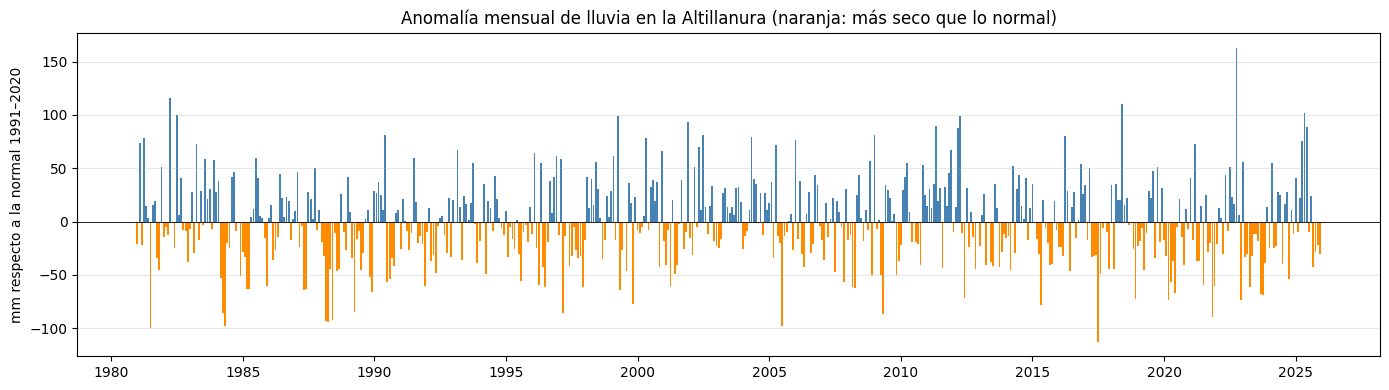

In [5]:
lluvia['mes_num'] = lluvia['fecha'].dt.month
ref = lluvia[lluvia['anio'].between(1991, 2020)]
clim = ref.groupby(['mpio_cdpmp', 'mes_num'])['lluvia_mm'].mean().rename('normal_mm')

lluvia = lluvia.drop(columns=['normal_mm'], errors='ignore').merge(
    clim, on=['mpio_cdpmp', 'mes_num'])
lluvia['anom_mm'] = lluvia['lluvia_mm'] - lluvia['normal_mm']
lluvia['anom_pct'] = np.where(lluvia['normal_mm'] > 0,
                              lluvia['anom_mm'] / lluvia['normal_mm'] * 100, np.nan)

# Anomalía regional (ponderada) para el gráfico
clim_reg = region.loc['1991':'2020'].groupby(region.loc['1991':'2020'].index.month).mean()
anom_reg = region - region.index.month.map(clim_reg).values

fig, ax = plt.subplots(figsize=(14, 4))
colores = np.where(anom_reg.values < 0, 'darkorange', 'steelblue')
ax.bar(anom_reg.index, anom_reg.values, width=25, color=colores)
ax.axhline(0, color='black', linewidth=0.6)
ax.set_title('Anomalía mensual de lluvia en la Altillanura (naranja: más seco que lo normal)')
ax.set_ylabel('mm respecto a la normal 1991–2020')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f'{FIGURAS}/05_anomalia_lluvia.png', dpi=150)
plt.show()

## Paso 6. La cadena El Niño → lluvia → fuego, por temporadas
Para cada temporada *y*:
- `lluvia_seca`: lluvia de diciembre de *y−1* a marzo de *y*.
- `lluvia_humeda_prev`: lluvia de abril a noviembre de *y−1*
  (hipótesis del combustible).
- `oni_nov_feb`: ONI promedio de noviembre de *y−1* a febrero de *y*.

                                                  n  spearman      p
1. ONI → lluvia de la temporada seca           44.0     -0.35  0.018
2. Lluvia de la temporada seca → fuego         22.0     -0.76  0.000
3. Lluvia húmeda previa → fuego (combustible)  22.0     -0.19  0.402
   (referencia) ONI → fuego                    22.0      0.33  0.135


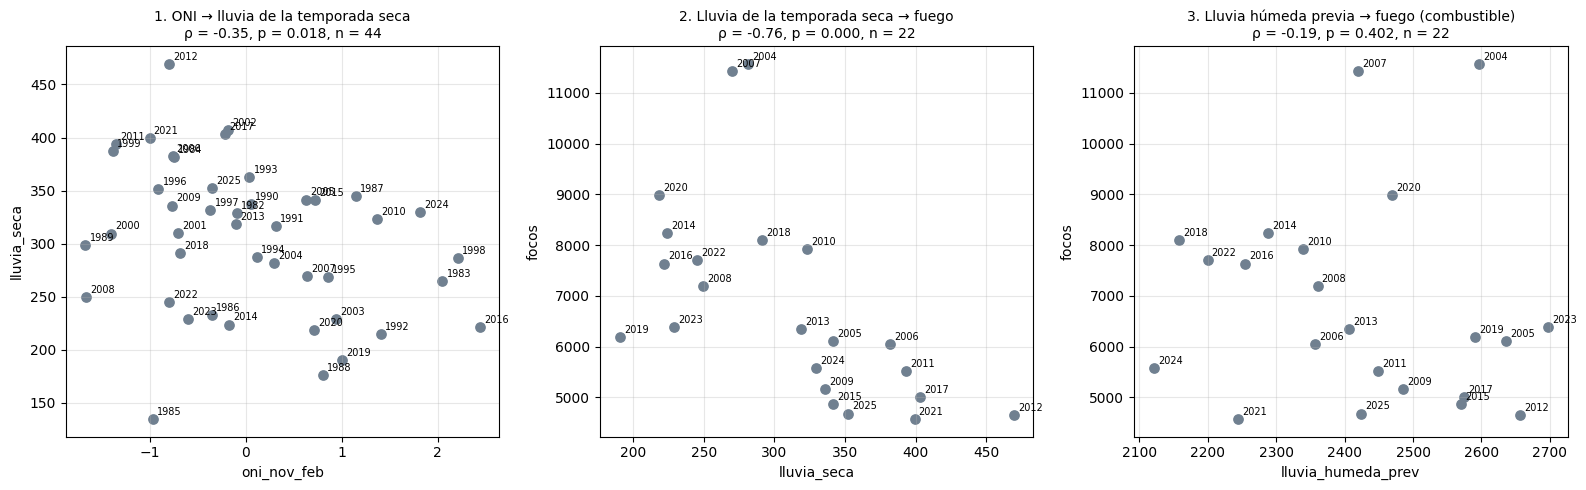

In [6]:
def por_temporada(serie, meses, desplazar):
    """Suma por temporada. `desplazar`: meses que pertenecen a la temporada siguiente."""
    s = serie[serie.index.month.isin(meses)]
    anio = np.where(s.index.month.isin(desplazar), s.index.year + 1, s.index.year)
    suma = s.groupby(anio).sum()
    n = s.groupby(anio).size()
    return suma[n == len(meses)]

lluvia_seca = por_temporada(region, [12, 1, 2, 3], desplazar=[12])
lluvia_humeda = por_temporada(region, list(range(4, 12)), desplazar=list(range(4, 12)))

oni = pd.read_csv(f'{PROCESADOS}/oni_mensual.csv', parse_dates=['fecha']).set_index('fecha')['oni']
o = oni[oni.index.month.isin([11, 12, 1, 2])]
anio_o = np.where(o.index.month >= 11, o.index.year + 1, o.index.year)
oni_temp = o.groupby(anio_o).mean()

focos = pd.read_csv(f'{PROCESADOS}/fuego_oni_temporadas.csv').set_index('temporada')['focos_temporada']

temp = pd.DataFrame({'oni_nov_feb': oni_temp,
                     'lluvia_seca': lluvia_seca,
                     'lluvia_humeda_prev': lluvia_humeda,
                     'focos': focos})
temp = temp.loc[1982:2025]
temp.index.name = 'temporada'

def correlacion(x, y, datos):
    d = datos[[x, y]].dropna()
    rho, p = stats.spearmanr(d[x], d[y])
    return pd.Series({'n': len(d), 'spearman': round(rho, 2), 'p': round(p, 3)})

pruebas = {
    '1. ONI → lluvia de la temporada seca': ('oni_nov_feb', 'lluvia_seca'),
    '2. Lluvia de la temporada seca → fuego': ('lluvia_seca', 'focos'),
    '3. Lluvia húmeda previa → fuego (combustible)': ('lluvia_humeda_prev', 'focos'),
    '   (referencia) ONI → fuego': ('oni_nov_feb', 'focos'),
}
resultados = pd.DataFrame({k: correlacion(*v, temp) for k, v in pruebas.items()}).T
print(resultados.to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (titulo, (x, y)) in zip(axes, list(pruebas.items())[:3]):
    d = temp[[x, y]].dropna()
    ax.scatter(d[x], d[y], color='slategray', s=45)
    for anio, fila in d.iterrows():
        ax.annotate(str(anio), (fila[x], fila[y]), fontsize=7,
                    xytext=(3, 3), textcoords='offset points')
    r = resultados.loc[titulo]
    ax.set_title(f"{titulo.strip()}\nρ = {r['spearman']:+.2f}, p = {r['p']:.3f}, n = {int(r['n'])}",
                 fontsize=10)
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIGURAS}/05_cadena_oni_lluvia_fuego.png', dpi=150)
plt.show()

## Paso 7. Mes a mes, solo en la temporada seca
Correlación entre las anomalías de fuego y de lluvia en dic–mar,
con la lluvia del mismo mes y la del mes anterior.

In [7]:
log_f = np.log1p(fuego_reg)
anom_f = log_f - log_f.groupby(log_f.index.month).transform('mean')

a_ll = anom_reg.reindex(anom_reg.index.union(anom_f.index)).sort_index()
secos = anom_f.index.month.isin([12, 1, 2, 3])

for rezago, texto in [(0, 'mismo mes'), (1, 'mes anterior'), (2, 'dos meses antes')]:
    x = a_ll.shift(rezago).reindex(anom_f.index)[secos]
    y = anom_f[secos]
    d = pd.concat([x, y], axis=1).dropna()
    rho, p = stats.spearmanr(d.iloc[:, 0], d.iloc[:, 1])
    print(f'Lluvia del {texto:16s} → fuego:  ρ = {rho:+.2f}  (p = {p:.3f}, n = {len(d)})')

Lluvia del mismo mes        → fuego:  ρ = -0.70  (p = 0.000, n = 92)
Lluvia del mes anterior     → fuego:  ρ = -0.13  (p = 0.211, n = 92)
Lluvia del dos meses antes  → fuego:  ρ = -0.06  (p = 0.566, n = 92)


## Paso 8. Guardar resultados

In [8]:
cols = ['mpio_cdpmp', 'mpio_cnmbr', 'mes', 'lluvia_mm', 'normal_mm', 'anom_mm', 'anom_pct']
lluvia[cols].sort_values(['mpio_cdpmp', 'mes']).to_csv(salida, index=False)
temp.reset_index().to_csv(f'{PROCESADOS}/clima_fuego_temporadas.csv', index=False)

chk = pd.read_csv(salida)
print('Guardado OK |', len(chk), 'filas mensuales |', len(temp), 'temporadas')

Guardado OK | 3780 filas mensuales | 44 temporadas
